# 🔴 Implement for H1 (some codes are common)

## ⚪ 1. Libraries

In [ ]:
import pandas as pd
import scipy.io
import numpy as np
from scipy.io import loadmat
from sklearn.preprocessing import MinMaxScaler
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt
from tqdm import tqdm

## ⚪ 2. Extract indices from .csv file

In [ ]:
# Define the path to your CSV file.
csv_file_path = 'thyroidori.csv'

In [ ]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    df_original = pd.read_csv(csv_file_path, header=None) #, header=None
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

    num_cols = df_original.shape[1]

    # For better readability, let's assign names to the columns.
    column_names = [f"c{i}" for i in range(1, num_cols)] + ["label"]
    df_original.columns = column_names

    # --- Step 2: Apply the condition to define the h1 subset ---
    condition = (df_original['c2'] >= 0) & (df_original['c2'] <= 0.5)

    # Create the h1 subset dataframe by applying the filter
    df_h1 = df_original[condition]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    h1_indices = df_h1.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in h1 ---
    h1_label_counts = df_h1['label'].value_counts()

    # --- Output and Verification ---
    print(f"Number of samples satisfying the h1 condition: {len(h1_indices)}")

    # Display the number of outliers in h1.
    print(f"Number of outliers in the h1 subset: {h1_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (3772, 7) (rows, columns)
Number of samples satisfying the T1 condition: 3766
Number of outliers in the T1 subset: label
1    3679
2      87
Name: count, dtype: int64


## ⚪ 3. Making X_tem from h1 indices italicized text

In [ ]:
print("Shape of h1: ", h1_indices.shape, )
print()
print("index of h1 :", h1_indices)
print()
print("type of h1: ", type(h1_indices))

Shape of T1:  (3766,)

index of T1 : [   0    1    2 ... 3769 3770 3771]

type of T1:  <class 'numpy.ndarray'>


In [ ]:
# Conver h1_indices to python list
X_tem1 = h1_indices.tolist()

## ⚪ 4. Checking .mat file

In [ ]:
mat = scipy.io.loadmat('thyroid.mat')
print(mat.keys())
print(pd.DataFrame(mat['trandata']).describe())

# mat['trandata']

dict_keys(['__header__', '__version__', '__globals__', 'trandata'])
                 0            1            2            3            4  \
count  3772.000000  3772.000000  3772.000000  3772.000000  3772.000000   
mean      0.543121     0.008983     0.186826     0.248332     0.376941   
std       0.203790     0.043978     0.070405     0.080579     0.087382   
min       0.000000     0.000000     0.000000     0.000000     0.000000   
25%       0.376344     0.001132     0.156546     0.203271     0.328638   
50%       0.569892     0.003019     0.190702     0.241822     0.375587   
75%       0.709677     0.004528     0.213472     0.282710     0.413146   
max       1.000000     1.000000     1.000000     1.000000     1.000000   

                 5            6  
count  3772.000000  3772.000000  
mean      0.177301     0.024655  
std       0.054907     0.155093  
min       0.000000     0.000000  
25%       0.149180     0.000000  
50%       0.173770     0.000000  
75%       0.196721     0.00

In [ ]:
pd.DataFrame(mat['trandata']).head()

,0,1,2,3,4,5,6
0,0.774194,0.001132,0.137571,0.275701,0.295775,0.236066,0.0
1,0.247312,0.000472,0.279886,0.329439,0.535211,0.173770,0.0
2,0.494624,0.003585,0.222960,0.233645,0.525822,0.124590,0.0
3,0.677419,0.001698,0.156546,0.175234,0.333333,0.136066,0.0
4,0.236559,0.000472,0.241935,0.320093,0.333333,0.247541,0.0


## ⚪ 5. Main code of 3WNCROD

In [ ]:
def WNCROD(data, X_tem, lammda):

    n, m = data.shape
    X = np.zeros(n)
    X[X_tem] = 1

    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m

    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    delta[ID] = np.std(data[:, ID], axis=0) / lammda

    Lower = np.zeros((m, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))

    n_X = int(sum(X))

    weight = np.zeros((n_X, m))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        weight_x = []

        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            weight_temp = 1 - (np.sqrt((np.sum(np.minimum(temp1, X))) / n_X))
            weight_x.append(weight_temp)

        weight[:len(weight_x), col] = weight_x

    D_tem = np.zeros((n, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem

    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]

    NEB_num = np.zeros((n_X, m))
    Lower_num = np.zeros((n_X, m))
    NPB_num = np.zeros((n_X, m))

    for col in range(m):
        temp2 = Lower[col, :]
        temp3 = NPB[col, :]

        for i in range(n_X):
            temp1 = X_OM[i, :]
            NEB_num[i, col] = np.sum(np.minimum(NEB[X_tem], temp1 <= D1))
            NPB_num[i, col] = np.sum(np.minimum(temp3[X_tem], temp1 >= D2))
            Lower_num[i, col] = np.sum(np.minimum(temp2[X_tem], temp1 >= D3))

    MNOF = np.mean(((NEB_num + Lower_num + NPB_num) / n_X) * weight, axis=1)
    return MNOF


## ⚪ 6. Run algorythm for h1

In [ ]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X1 = full_data[:, :6]                   # First 6 columns
    y1 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 0, 1, 2, 3, 4, 5)
    numeric_idx = [0, 1, 2, 3, 4, 5]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X1[:, numeric_idx] = scaler.fit_transform(X1[:, numeric_idx])

    # 4) Run the algorithm with the same X_tem and lammda=2.0
    out_scores = WNCROD(X1, X_tem1, lammda=2.0)

    # 5) Extract true labels only for X_tem1
    y_true = y1[X_tem1]

    # 6) Compute metrics
    roc_auc1 = roc_auc_score(y_true, out_scores)
    ap1      = average_precision_score(y_true, out_scores)

    print(f"ROC-AUC: {roc_auc1:.4f}")
    print(f"Average Precision (AP): {ap1:.4f}")

ROC-AUC: 0.9764
Average Precision (AP): 0.7159


In [ ]:
if __name__ == "__main__":

    # 0) لیست 10 مقدار λ که می‌خواهید تست کنید
    lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2.0,
                   2.1, 2.2, 2.3, 2.4, 2.5]

    # 1) Load data
    mat       = loadmat('german_1_14_varianh1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 21)

    # 2) Separate features and labels
    X1 = full_data[:, :20]                   # First 20 columns
    y1 = full_data[:, 20].astype(int)        # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15)
    numeric_idx = [1, 4, 7, 10, 12, 15]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X1[:, numeric_idx] = scaler.fit_transform(X1[:, numeric_idx])

    # 4) True labels for G1 (فرض بر این است که X_tem از قبل تعریف شده)
    y_true = y1[X_tem1]

    # 5) حلقه روی همه λها و محاسبهٔ خروجی و معیارها
    results = []
    for lam in lambda_list:
        out_scores = WNCROD(X1, X_tem1, lammda=lam)

        # محاسبهٔ معیارها
        roc_auc = roc_auc_score(y_true, out_scores)
        ap      = average_precision_score(y_true, out_scores)

        results.append({
            'lambda': lam,
            'ROC-AUC': roc_auc,
            'AP': ap
        })

    # 6) نمایش نتایج
    for r in results:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

λ = 0.1 | ROC-AUC = 0.0357 | AP = 0.0085
λ = 0.2 | ROC-AUC = 0.0244 | AP = 0.0085
λ = 0.3 | ROC-AUC = 0.0164 | AP = 0.0085
λ = 0.4 | ROC-AUC = 0.9799 | AP = 0.5117
λ = 0.5 | ROC-AUC = 0.9823 | AP = 0.5268
λ = 0.6 | ROC-AUC = 0.9859 | AP = 0.5590
λ = 0.7 | ROC-AUC = 0.9844 | AP = 0.5609
λ = 0.8 | ROC-AUC = 0.9831 | AP = 0.5533
λ = 0.9 | ROC-AUC = 0.9818 | AP = 0.5410
λ = 1.0 | ROC-AUC = 0.9776 | AP = 0.5220
λ = 1.1 | ROC-AUC = 0.9769 | AP = 0.5214
λ = 1.2 | ROC-AUC = 0.9872 | AP = 0.5164
λ = 1.3 | ROC-AUC = 0.9874 | AP = 0.5171
λ = 1.4 | ROC-AUC = 0.9872 | AP = 0.5145
λ = 1.5 | ROC-AUC = 0.9868 | AP = 0.5104
λ = 1.6 | ROC-AUC = 0.9868 | AP = 0.5104
λ = 1.7 | ROC-AUC = 0.9865 | AP = 0.5034
λ = 1.8 | ROC-AUC = 0.9863 | AP = 0.5013
λ = 1.9 | ROC-AUC = 0.9865 | AP = 0.5037
λ = 2.0 | ROC-AUC = 0.9865 | AP = 0.5057
λ = 2.1 | ROC-AUC = 0.9863 | AP = 0.5027
λ = 2.2 | ROC-AUC = 0.9863 | AP = 0.5027
λ = 2.3 | ROC-AUC = 0.9857 | AP = 0.4966
λ = 2.4 | ROC-AUC = 0.9857 | AP = 0.4959
λ = 2.5 | ROC-AU

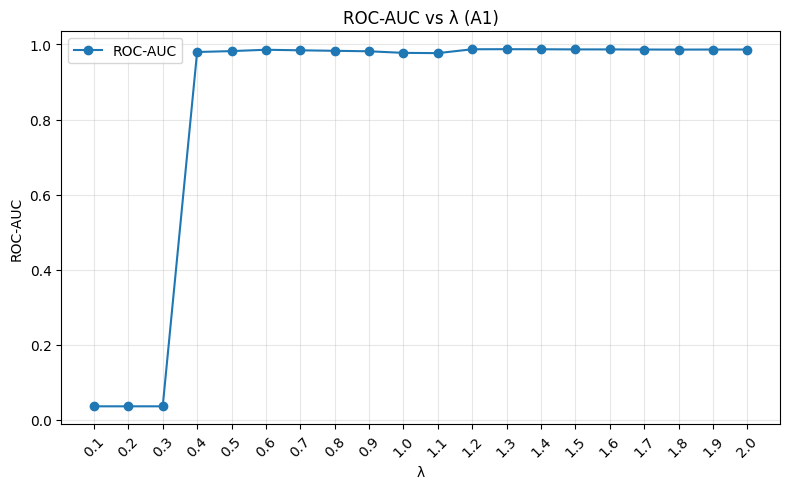

In [ ]:
# لیست λها و مقادیر متناظر ROC-AUC
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]

roc_auc_list = [0.0357, 0.0357, 0.0357, 0.9799, 0.9823,
                0.9859, 0.9844, 0.9831, 0.9818, 0.9776,
                0.9769, 0.9872, 0.9874, 0.9872, 0.9868,
                0.9868, 0.9865, 0.9863, 0.9865, 0.9865]

# رسم نمودار
plt.figure(figsize=(8, 5))
plt.plot(lambda_list, roc_auc_list, marker='o', linestyle='-',
         color='C0', label='ROC-AUC')
plt.title('ROC-AUC vs λ (h1)')
plt.xlabel('λ')
plt.ylabel('ROC-AUC')
plt.xticks(lambda_list, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## ⚪ 7. Radius Neighborhood for G1

In [ ]:
    n, m = X1.shape
    lammda = 2.0
    delta = np.zeros(m)
    ID = np.all(X1 <= 1, axis=0)
    delta[ID] = np.std(X1[:, ID], axis=0) / lammda

    print(f"Neighborhood radius for each {X1.shape[1]} Features with λ = {lammda} for G1:")
    for idx, d in enumerate(delta, start=1):
        print(f"  Feature : {idx:2d}: δ(Neighborhood radius ) = {d:.6f}")

Neighborhood radius for each 20 Features with λ = 2.0 for G1:
  Feature :  1: δ(Neighborhood radius ) = 0.000000
  Feature :  2: δ(Neighborhood radius ) = 0.102455
  Feature :  3: δ(Neighborhood radius ) = 0.000000
  Feature :  4: δ(Neighborhood radius ) = 0.000000
  Feature :  5: δ(Neighborhood radius ) = 0.071423
  Feature :  6: δ(Neighborhood radius ) = 0.000000
  Feature :  7: δ(Neighborhood radius ) = 0.000000
  Feature :  8: δ(Neighborhood radius ) = 0.188049
  Feature :  9: δ(Neighborhood radius ) = 0.000000
  Feature : 10: δ(Neighborhood radius ) = 0.000000
  Feature : 11: δ(Neighborhood radius ) = 0.184636
  Feature : 12: δ(Neighborhood radius ) = 0.000000
  Feature : 13: δ(Neighborhood radius ) = 0.103085
  Feature : 14: δ(Neighborhood radius ) = 0.000000
  Feature : 15: δ(Neighborhood radius ) = 0.000000
  Feature : 16: δ(Neighborhood radius ) = 0.098027
  Feature : 17: δ(Neighborhood radius ) = 0.000000
  Feature : 18: δ(Neighborhood radius ) = 0.183147
  Feature : 19: δ(Ne

# 🔴 Implement for h2

## ⚪ 2. Extract indices from .csv file

In [ ]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    # df_original = pd.read_csv(csv_file_path, header=None)
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

    num_cols = df_original.shape[1]

    # For better readability, let's assign names to the columns.
    column_names = [f"c{i}" for i in range(1, num_cols)] + ["label"]
    df_original.columns = column_names

    # --- Step 2: Apply the condition2 to define the h2 subset ---
    condition2 = (df_original['c6'] >= 0) & (df_original['c6'] <= 0.3)

    # Create the h2 subset dataframe by applying the filter
    df_h2 = df_original[condition2]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    h2_indices = df_h2.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in h2 ---
    h2_label_counts = df_h2['label'].value_counts()

    # --- Output and Verification ---
    print(f"Number of samples satisfying the h2 condition: {len(h2_indices)}")

    # Display the number of outliers in h2.
    print(f"Number of outliers in the h2 subset: {h2_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (3772, 7) (rows, columns)
Number of samples satisfying the TH2 condition: 3676
Number of outliers in the TH2 subset: label
1    3583
2      93
Name: count, dtype: int64


## ⚪ 3. Making X_tem from h2 indices italicized text

In [ ]:
# Conver h2_indices to python list
X_tem2 = h2_indices.tolist()

## ⚪ 6. Run algorythm for h2

In [ ]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X2 = full_data[:, :6]                   # First 6 columns
    y2 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X2[:, 1:] = scaler.fit_transform(X2[:, 1:])

    # 4) Run the algorithm with the same X_tem2 and lammda=2.0
    out_scores2 = WNCROD(X2, X_tem2, lammda=2.0)

    # 5) Extract true labels only for X_tem2
    y_true2 = y2[X_tem2]

    # 6) Compute metrics
    roc_auc_h2 = roc_auc_score(y_true2, out_scores2)
    ap_h2      = average_precision_score(y_true2, out_scores2)

    print(f"ROC-AUC: {roc_auc_h2:.4f}")
    print(f"Average Precision (AP): {ap_h2:.4f}")

ROC-AUC: 0.9822
Average Precision (AP): 0.4261


In [ ]:
if __name__ == "__main__":
    # لیست λهایی که می‌خواهید تست کنید
    lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2.0]

    # 1) بارگذاری داده
    mat       = loadmat('german_1_14_varianh1.mat')
    full_data = mat['trandata']            # شکل: (n_samples, 7)

    # 2) جدا کردن ویژگی‌ها و برچسب‌ها
    X2 = full_data[:, :20]                  # 6 ستون اول
    y2 = full_data[:, 20].astype(int)       # ستون 7 (اندیس 6)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15)
    numeric_idx = [1, 4, 7, 10, 12, 15]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X2[:, numeric_idx] = scaler.fit_transform(X2[:, numeric_idx])

    # 4) برچسب‌های واقعی برای نمونه‌های X_tem2
    y_true2 = y2[X_tem2]

    # 5) حلقه برای اجرای WNCROD با مقادیر مختلف λ و محاسبه معیارها
    results2 = []
    for lam in lambda_list:
        out_scores2 = WNCROD(X2, X_tem2, lammda=lam)
        roc2 = roc_auc_score(y_true2, out_scores2)
        ap2  = average_precision_score(y_true2, out_scores2)
        results2.append({
            'lambda': lam,
            'ROC-AUC': roc2,
            'AP': ap2
        })

    # 6) نمایش نتایج
    print("نتایج h2 برای λهای مختلف:")
    for r in results2:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")

نتایج G2 برای λهای مختلف:
λ = 0.1 | ROC-AUC = 0.9464 | AP = 0.2682
λ = 0.2 | ROC-AUC = 0.9630 | AP = 0.3153
λ = 0.3 | ROC-AUC = 0.9770 | AP = 0.4022
λ = 0.4 | ROC-AUC = 0.9821 | AP = 0.5432
λ = 0.5 | ROC-AUC = 0.9849 | AP = 0.5373
λ = 0.6 | ROC-AUC = 0.9863 | AP = 0.5331
λ = 0.7 | ROC-AUC = 0.9857 | AP = 0.5218
λ = 0.8 | ROC-AUC = 0.9849 | AP = 0.5196
λ = 0.9 | ROC-AUC = 0.9834 | AP = 0.5024
λ = 1.0 | ROC-AUC = 0.9802 | AP = 0.4908
λ = 1.1 | ROC-AUC = 0.9791 | AP = 0.4941
λ = 1.2 | ROC-AUC = 0.9836 | AP = 0.4280
λ = 1.3 | ROC-AUC = 0.9842 | AP = 0.4488
λ = 1.4 | ROC-AUC = 0.9842 | AP = 0.4488
λ = 1.5 | ROC-AUC = 0.9832 | AP = 0.4256
λ = 1.6 | ROC-AUC = 0.9829 | AP = 0.4231
λ = 1.7 | ROC-AUC = 0.9830 | AP = 0.4304
λ = 1.8 | ROC-AUC = 0.9830 | AP = 0.4304
λ = 1.9 | ROC-AUC = 0.9832 | AP = 0.4317
λ = 2.0 | ROC-AUC = 0.9822 | AP = 0.4261


## ⚪ 7. Radius Neighborhood for h2

In [ ]:
    n, m = X2.shape
    lammda = 2.0
    delta = np.zeros(m)
    ID = np.all(X2 <= 1, axis=0)
    delta[ID] = np.std(X2[:, ID], axis=0) / lammda

    print(f"Neighborhood radius for each {X2.shape[1]} Features with λ = {lammda} for h2:")
    for idx, d in enumerate(delta, start=1):
        print(f"  Feature : {idx:2d}: δ(Neighborhood radius ) = {d:.6f}")

Neighborhood radius for each 20 Features with λ = 2.0 for G2:
  Feature :  1: δ(Neighborhood radius ) = 0.000000
  Feature :  2: δ(Neighborhood radius ) = 0.102455
  Feature :  3: δ(Neighborhood radius ) = 0.000000
  Feature :  4: δ(Neighborhood radius ) = 0.000000
  Feature :  5: δ(Neighborhood radius ) = 0.071423
  Feature :  6: δ(Neighborhood radius ) = 0.000000
  Feature :  7: δ(Neighborhood radius ) = 0.000000
  Feature :  8: δ(Neighborhood radius ) = 0.188049
  Feature :  9: δ(Neighborhood radius ) = 0.000000
  Feature : 10: δ(Neighborhood radius ) = 0.000000
  Feature : 11: δ(Neighborhood radius ) = 0.184636
  Feature : 12: δ(Neighborhood radius ) = 0.000000
  Feature : 13: δ(Neighborhood radius ) = 0.103085
  Feature : 14: δ(Neighborhood radius ) = 0.000000
  Feature : 15: δ(Neighborhood radius ) = 0.000000
  Feature : 16: δ(Neighborhood radius ) = 0.098027
  Feature : 17: δ(Neighborhood radius ) = 0.000000
  Feature : 18: δ(Neighborhood radius ) = 0.183147
  Feature : 19: δ(Ne

# 🔴 Implement for h3

## ⚪ 2. Extract indices from .csv file

In [ ]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    # df_original = pd.read_csv(csv_file_path, header=None)
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")
    num_cols = df_original.shape[1]

    # For better readability, let's assign names to the columns.
    column_names = [f"c{i}" for i in range(1, num_cols)] + ["label"]
    df_original.columns = column_names

    # --- Step 2: Apply the condition3 to define the h3 subset ---
    condition3 = (df_original['c5'] >= 0) & (df_original['c5'] <= 0.5)

    # Create the h3 subset dataframe by applying the filter
    df_h3 = df_original[condition3]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    h3_indices = df_h3.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in h3 ---
    h3_label_counts = df_h3['label'].value_counts()

    # --- Output and Verification ---
    print(f"h3 Condition: Feature 'c5' must be in the range [0, 0.5].")
    print(f"Total number of samples in the original dataset: {len(df_original)}")
    print(f"Number of samples satisfying the h3 condition: {len(h3_indices)}")

    # Display the first few indices for a quick check.
    print(f"First 10 indices of the h3 subset: {h3_indices[:10]}")

    # Display the number of outliers in h3.
    print(f"Number of outliers in the h3 subset: {h3_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (3772, 7) (rows, columns)
G3 Condition: Feature 'c5' must be in the range [0, 0.5].
Total number of samples in the original dataset: 3772
Number of samples satisfying the T3 condition: 3530
First 10 indices of the T3 subset: [ 0  3  4  5  6  7  8 10 11 12]
Number of outliers in the T3 subset: label
1    3447
2      83
Name: count, dtype: int64


## ⚪ 3. Making X_tem from h3 indices italicized text

In [ ]:
# Conver h3_indices to python list
X_tem3 = h3_indices.tolist()

## ⚪ 6. Run algorythm for h3

In [ ]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X3 = full_data[:, :6]                   # First 6 columns
    y3 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X3[:, 1:] = scaler.fit_transform(X3[:, 1:])

    # 4) Run the algorithm with the same X_tem3 and lammda=2.0
    out_scores3 = WNCROD(X3, X_tem3, lammda=2.0)

    # 5) Extract true labels only for X_tem3
    y_true3 = y3[X_tem3]

    # 6) Compute metrics
    roc_auc_h3 = roc_auc_score(y_true3, out_scores3)
    ap_h3      = average_precision_score(y_true3, out_scores3)

    print(f"ROC-AUC: {roc_auc_h3:.4f}")
    print(f"Average Precision (AP): {ap_h3:.4f}")

ROC-AUC: 0.9915
Average Precision (AP): 0.3623


In [ ]:

if __name__ == "__main__":
    # 1) مقادیر λ که می‌خواهید تست کنید
    lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
                   0.6, 0.7, 0.8, 0.9, 1.0,
                   1.1, 1.2, 1.3, 1.4, 1.5,
                   1.6, 1.7, 1.8, 1.9, 2.0]

    # 2) بارگذاری داده
    mat       = loadmat('german_1_14_varianh1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 21)

    # 3) جدا کردن ویژگی‌ها و برچسب‌ها
    X3 = full_data[:, :20]                  # First 20 columns
    y3 = full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15)
    numeric_idx = [1, 4, 7, 10, 12, 15]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X3[:, numeric_idx] = scaler.fit_transform(X3[:, numeric_idx])

    # 6) استخراج برچسب‌های واقعی برای X_tem3
    y_true3 = y3[X_tem3]

    # 7) اجرای حلقه برای همه λها و محاسبهٔ معیارها
    results3 = []
    for lam in lambda_list:
        out_scores3 = WNCROD(X3, X_tem3, lammda=lam)
        roc3 = roc_auc_score(y_true3, out_scores3)
        ap3  = average_precision_score(y_true3, out_scores3)
        results3.append({
            'lambda': lam,
            'ROC-AUC': roc3,
            'AP': ap3
        })

    # 8) نمایش نتایج
    print("نتایج h3 برای λهای مختلف:")
    for r in results3:
        print(f"λ = {r['lambda']:.1f} | ROC-AUC = {r['ROC-AUC']:.4f} | AP = {r['AP']:.4f}")



نتایج t3 برای λهای مختلف:
λ = 0.1 | ROC-AUC = 0.9737 | AP = 0.5983
λ = 0.2 | ROC-AUC = 0.9747 | AP = 0.3838
λ = 0.3 | ROC-AUC = 0.9590 | AP = 0.3359
λ = 0.4 | ROC-AUC = 0.9372 | AP = 0.2343
λ = 0.5 | ROC-AUC = 0.9355 | AP = 0.1885
λ = 0.6 | ROC-AUC = 0.9545 | AP = 0.4217
λ = 0.7 | ROC-AUC = 0.9741 | AP = 0.5871
λ = 0.8 | ROC-AUC = 0.9780 | AP = 0.6413
λ = 0.9 | ROC-AUC = 0.9812 | AP = 0.6762
λ = 1.0 | ROC-AUC = 0.9833 | AP = 0.6900
λ = 1.1 | ROC-AUC = 0.9851 | AP = 0.7280
λ = 1.2 | ROC-AUC = 0.9870 | AP = 0.7594
λ = 1.3 | ROC-AUC = 0.9883 | AP = 0.7825
λ = 1.4 | ROC-AUC = 0.9897 | AP = 0.8008
λ = 1.5 | ROC-AUC = 0.9913 | AP = 0.8178
λ = 1.6 | ROC-AUC = 0.9918 | AP = 0.8284
λ = 1.7 | ROC-AUC = 0.9919 | AP = 0.8361
λ = 1.8 | ROC-AUC = 0.9920 | AP = 0.8401
λ = 1.9 | ROC-AUC = 0.9924 | AP = 0.8493
λ = 2.0 | ROC-AUC = 0.9924 | AP = 0.8518
λ = 2.1 | ROC-AUC = 0.9923 | AP = 0.8574
λ = 2.2 | ROC-AUC = 0.9921 | AP = 0.8568
λ = 2.3 | ROC-AUC = 0.9924 | AP = 0.8552
λ = 2.4 | ROC-AUC = 0.9926 | AP

# 🔵 New Approach for h1

### 1. Main code of new 3WNCROD

In [ ]:
def NEW_WNCROD(data: np.ndarray, X_tem: list[int], lammda_list: list[float]) -> np.ndarray:

    n, m = data.shape
    lammda_arr = np.array(lammda_list, dtype=float)
    if lammda_arr.shape[0] != m:
        raise ValueError(f"The length of lammda_list must be equal to the #features : ({m}).")

    X = np.zeros(n, dtype=int)
    X[X_tem] = 1

    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m

    # Calculate independent neighborhood radius for each feature
    delta = np.zeros(m, dtype=float)
    ID = np.all(data <= 1, axis=0)
    stds = np.std(data[:, ID], axis=0)
    delta[ID] = stds / lammda_arr[ID]

    Lower = np.zeros((m, n), dtype=float)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    # IB, NEB, NPB
    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))

    # Weighting
    n_X = int(np.sum(X))
    weight = np.zeros((n_X, m), dtype=float)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        wcol = []
        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            wtemp = 1 - np.sqrt(np.sum(np.minimum(temp1, X)) / n_X)
            wcol.append(wtemp)
        weight[:, col] = wcol

    # D_tem & NOM
    D_tem = np.zeros((n, n), dtype=int)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem.astype(int)
    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]

    # counting : NEB_num, Lower_num, NPB_num
    NEB_num = np.zeros((n_X, m), dtype=int)
    Lower_num = np.zeros((n_X, m), dtype=int)
    NPB_num = np.zeros((n_X, m), dtype=int)
    for col in range(m):
        tLower = Lower[col, :]
        tNPB   = NPB[col, :]
        for i in range(n_X):
            row_OM = X_OM[i, :]
            NEB_num[i, col]   = np.sum(np.minimum(NEB[X_tem],    row_OM <= D1))
            NPB_num[i, col]   = np.sum(np.minimum(tNPB[X_tem],   row_OM >= D2))
            Lower_num[i, col] = np.sum(np.minimum(tLower[X_tem], row_OM >= D3))

    # calculate MNOF
    NDF = (NEB_num + Lower_num + NPB_num) / n_X
    MNOF = np.mean(NDF * weight, axis=1)
    return MNOF

### 2. runing algo

In [ ]:
# this is for best lammda list for TOP AP
if __name__ == "__main__":

    lammda = [0.1, 0.7, 0.1, 0.1, 0.6, 0.1, 0.1, 1.2, 0.1, 0.1, 0.4, 0.1, 0.6, 0.1, 0.1, 0.6, 0.1, 0.4, 0.1, 0.1]

    # 1) Load data
    mat       = loadmat('german_1_14_varianh1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 21)

    # 2) Separate features and labels
    X11 = full_data[:, :20]                   # First 20 columns
    y11 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15, 17)
    numeric_idx = [1, 4, 7, 10, 12, 15, 17]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X11[:, numeric_idx] = scaler.fit_transform(X11[:, numeric_idx])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores11 = NEW_WNCROD(X11, X_tem1, lammda)

    # 5) Extract true labels only for X_tem
    y_true11 = y11[X_tem1]

    # 6) Compute metrics
    roc_auc11 = roc_auc_score(y_true11, out_scores11)
    ap11      = average_precision_score(y_true11, out_scores11)

    print(f"ROC-AUC: {roc_auc11:.4f}")
    print(f"Average Precision (AP): {ap11:.4f}")

ROC-AUC: 0.9848
Average Precision (AP): 0.6701


In [ ]:
# this is for best lammda list for TOP ROC-AUC
if __name__ == "__main__":

    lammda = [0.1, 0.4, 0.1, 0.1, 0.3, 0.1, 0.1, 0.4, 0.1, 0.1, 1.2, 0.1, 0.6, 0.1, 0.1, 0.6, 0.1, 0.4, 0.1, 0.1]

    # 1) Load data
    mat       = loadmat('german_1_14_varianh1.mat')
    full_data = mat['trandata']            # shape = (n_samples, 21)

    # 2) Separate features and labels
    X11 = full_data[:, :20]                   # First 20 columns
    y11 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15, 17)
    numeric_idx = [1, 4, 7, 10, 12, 15, 17]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X11[:, numeric_idx] = scaler.fit_transform(X11[:, numeric_idx])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores11 = NEW_WNCROD(X11, X_tem1, lammda)

    # 5) Extract true labels only for X_tem
    y_true11 = y11[X_tem1]

    # 6) Compute metrics
    roc_auc11 = roc_auc_score(y_true11, out_scores11)
    ap11      = average_precision_score(y_true11, out_scores11)

    print(f"ROC-AUC: {roc_auc11:.4f}")
    print(f"Average Precision (AP): {ap11:.4f}")

ROC-AUC: 0.9891
Average Precision (AP): 0.5578


> 👉👉 **Its ok and it works. we claimed the same result for same lammda.** ✅
>
> **Now we will loking for improvments by searching for best lammda list. 👇👇👇**

### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [ ]:
def greedy_search_lambdas(X: np.ndarray,
                          y: np.ndarray,
                          X_tem: list[int],
                          candidates: list[float],
                          metric_name: str = 'AP'):

    m = X.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true = y[X_tem1]

    # Selecting the criterion function
    if metric_name.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name must be 'AP' or 'ROC'")

    # Loop over each feature
    for j in range(m):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X, X_tem, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix


=== Best Lambdas for AP for G1 ===
[0.1 0.7 0.1 0.1 0.6 0.1 0.1 1.2 0.1 0.1 0.4 0.1 0.6 0.1 0.1 0.6 0.1 0.4
 0.1 0.1]
=== Best Lambdas for ROC-AUC for G1===
[0.1 0.4 0.1 0.1 0.3 0.1 0.1 0.4 0.1 0.1 1.2 0.1 0.6 0.1 0.1 0.6 0.1 0.4
 0.1 0.1]


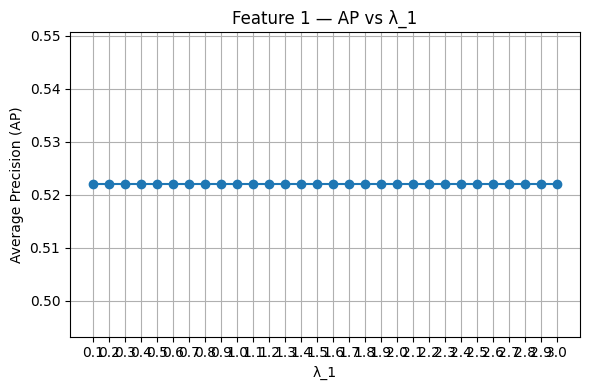

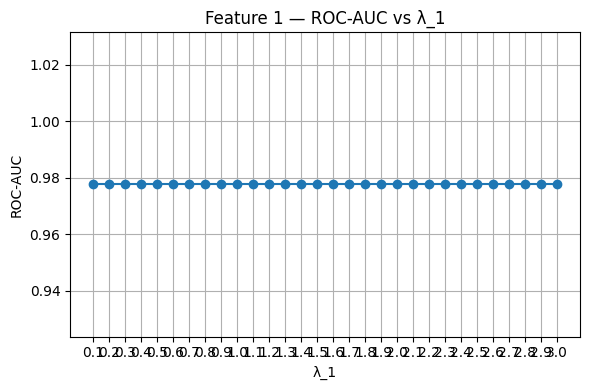

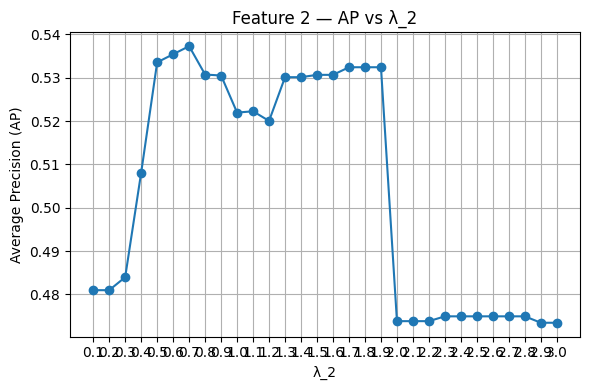

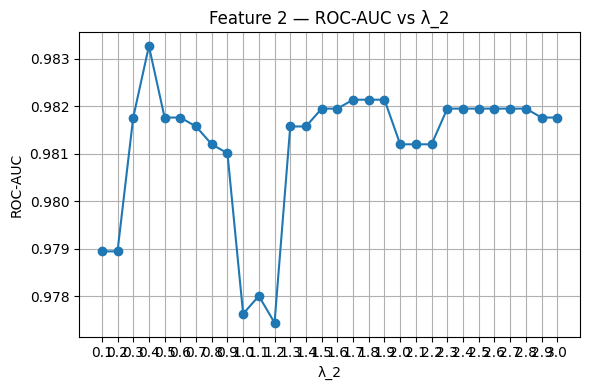

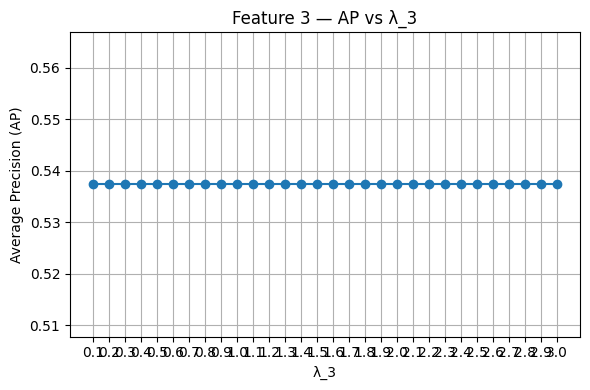

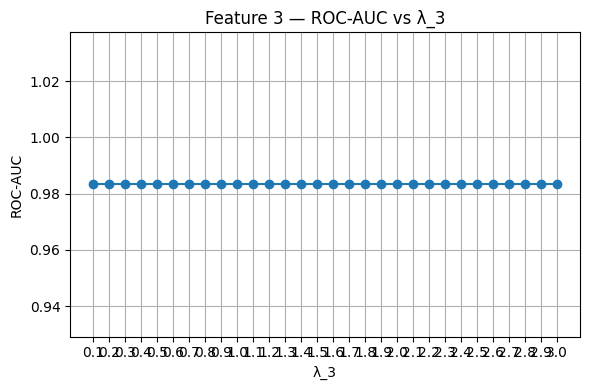

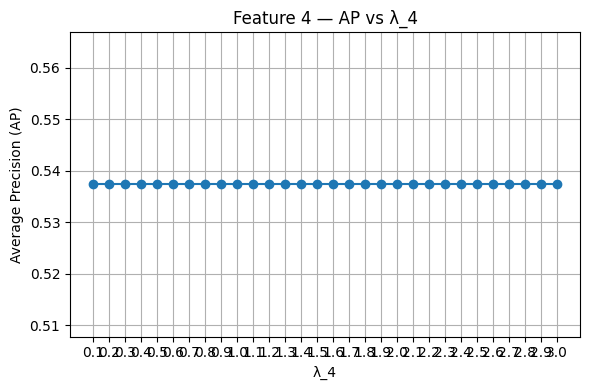

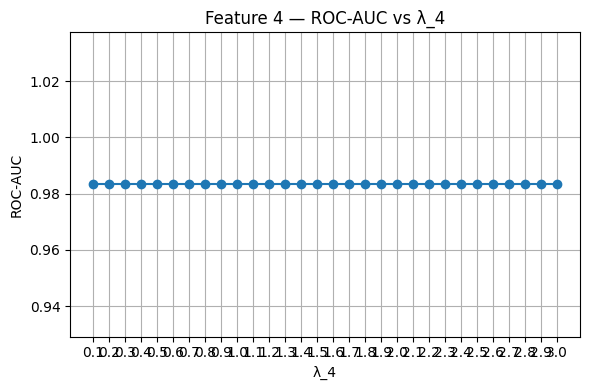

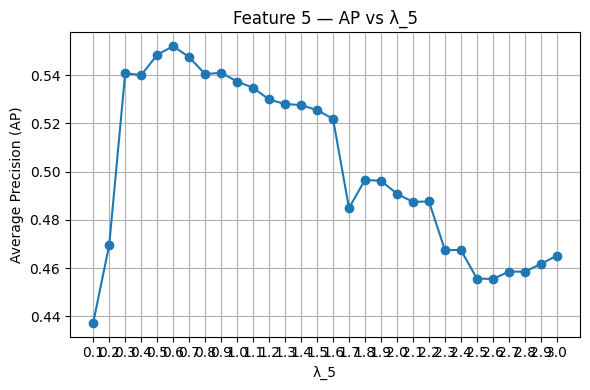

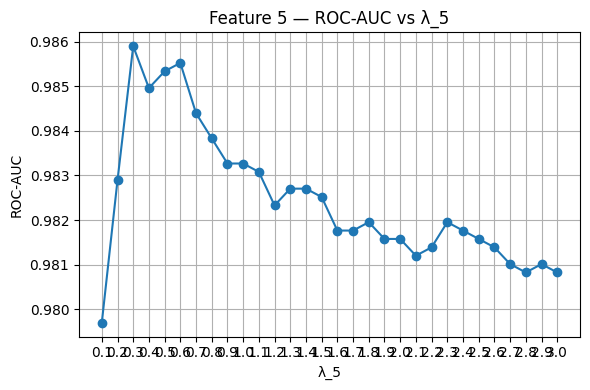

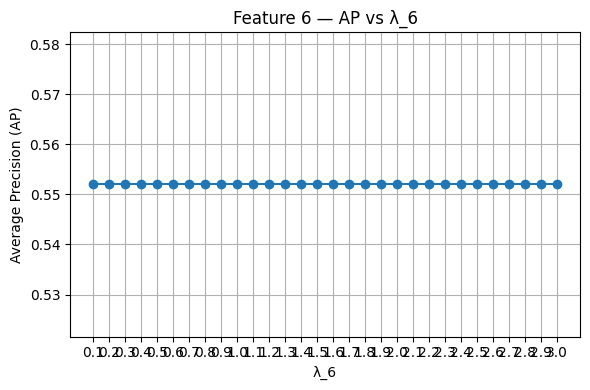

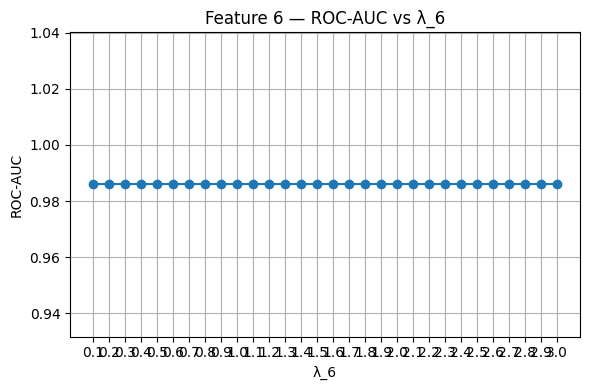

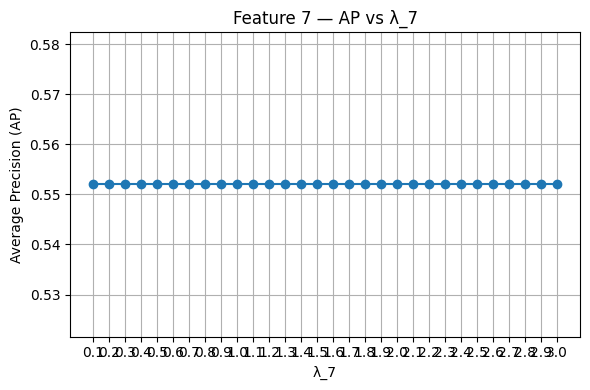

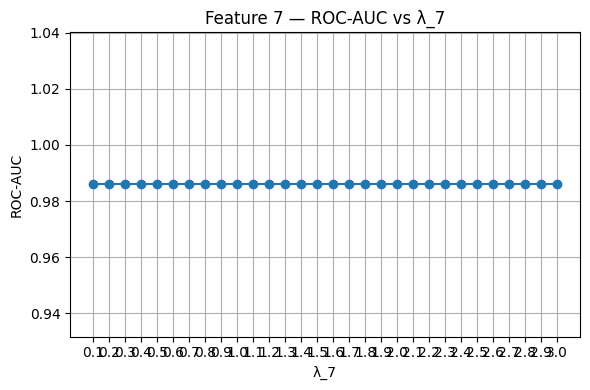

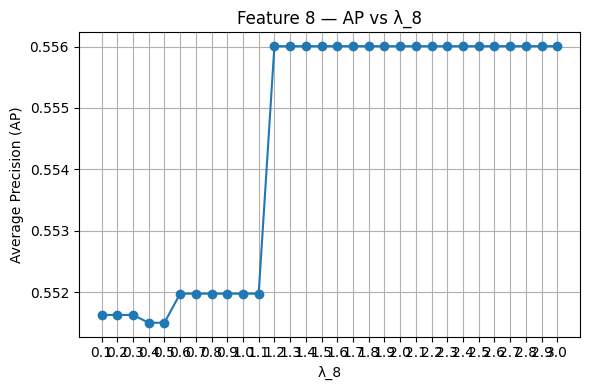

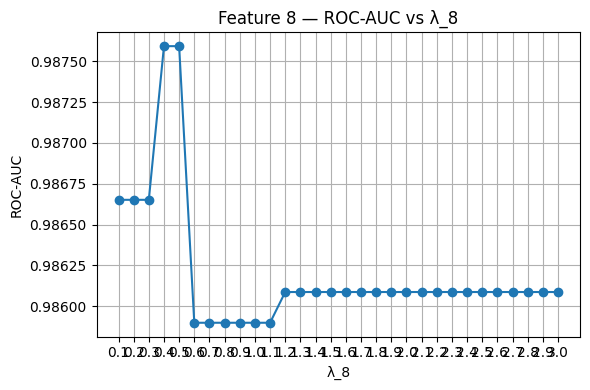

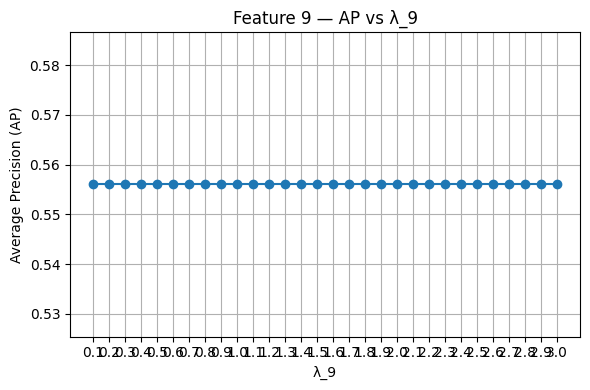

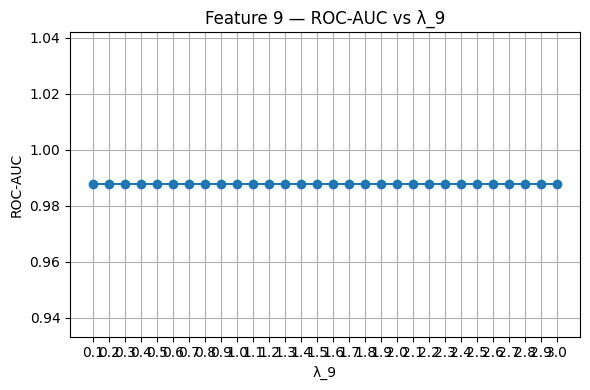

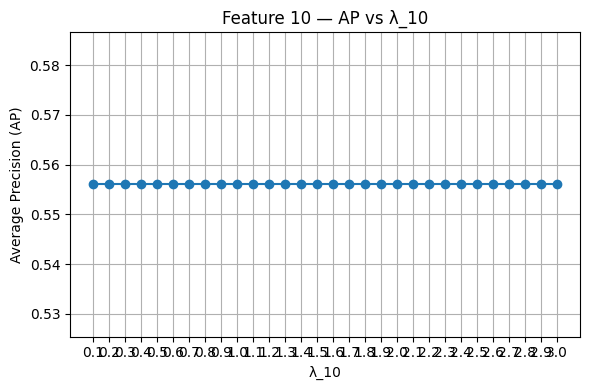

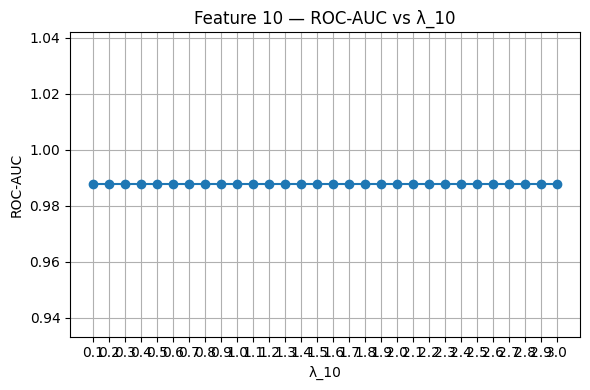

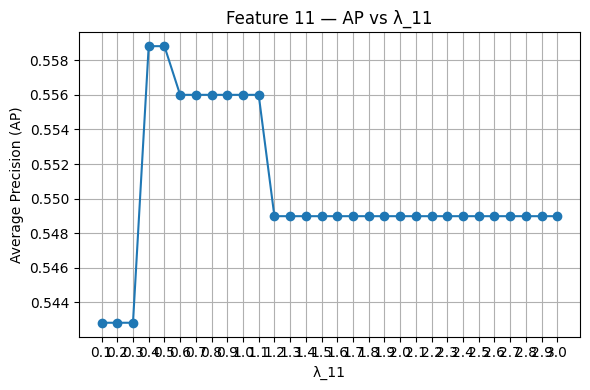

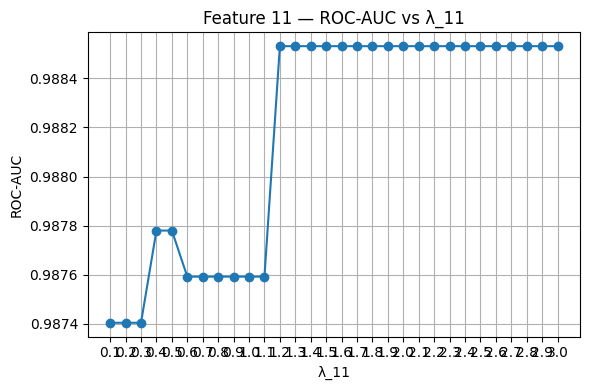

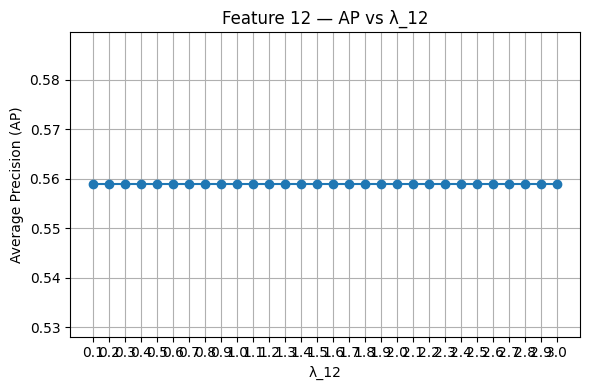

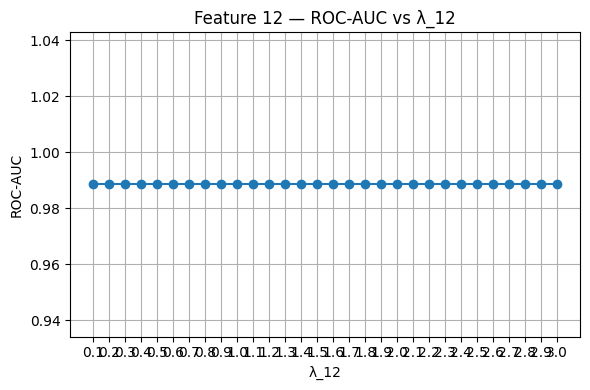

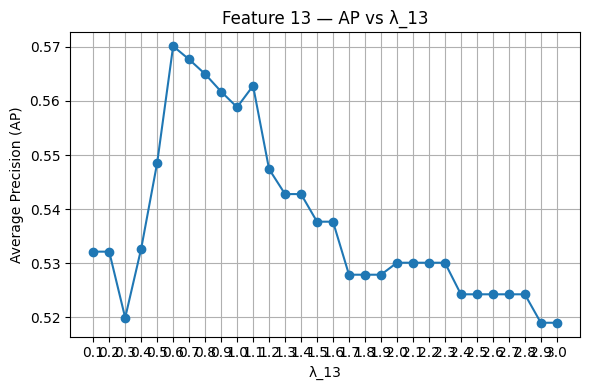

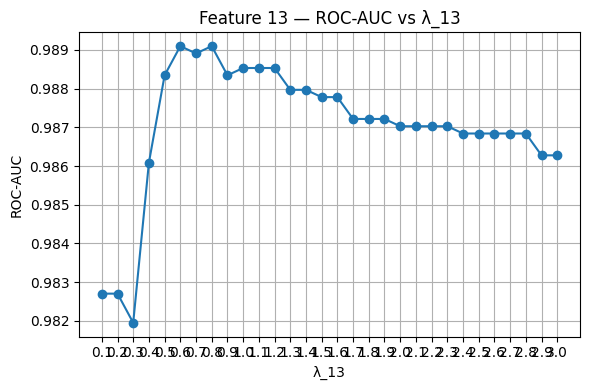

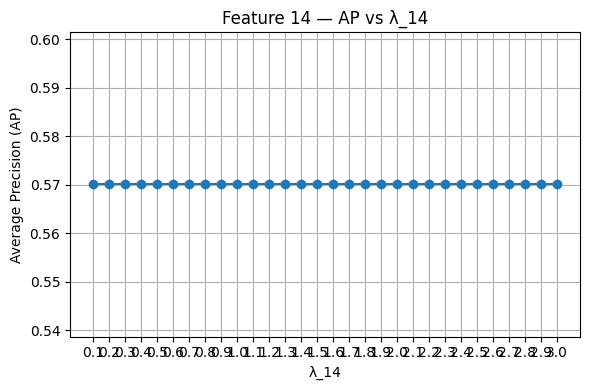

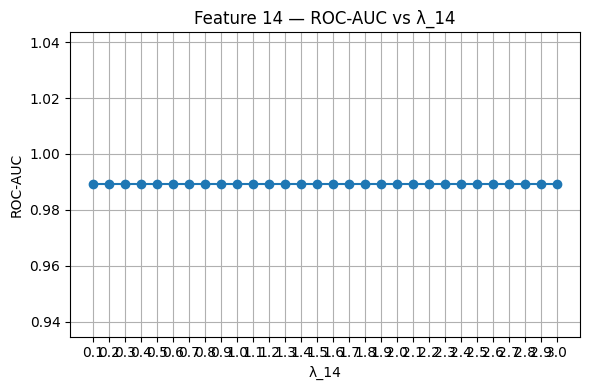

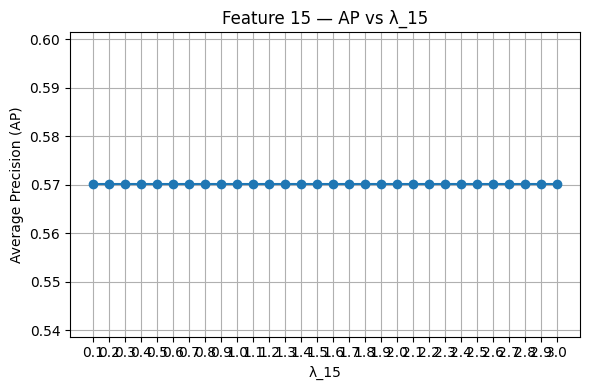

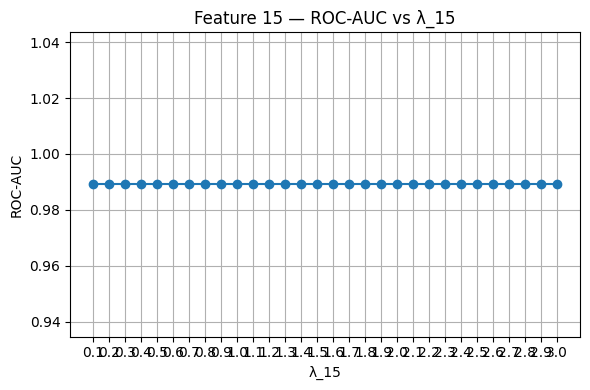

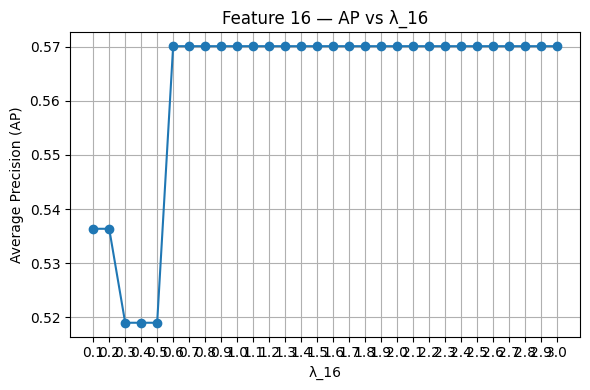

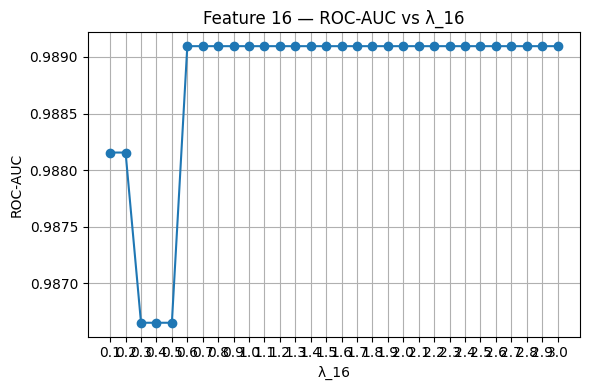

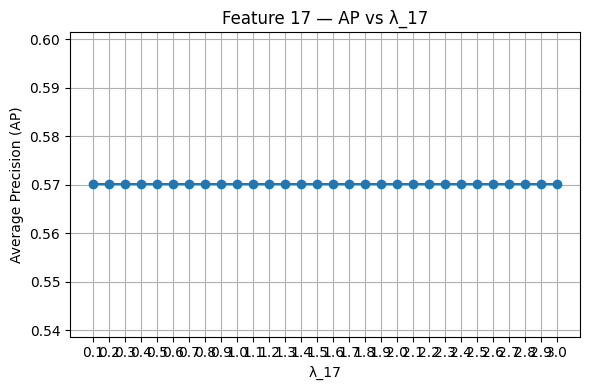

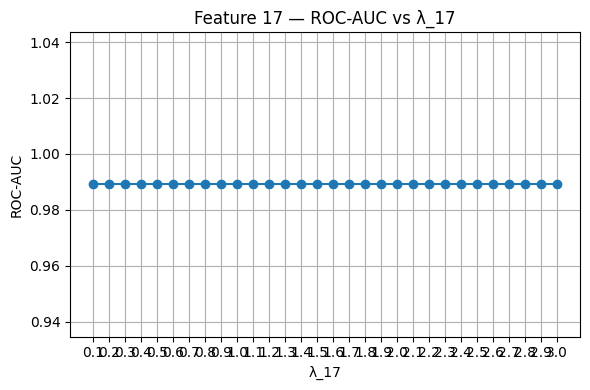

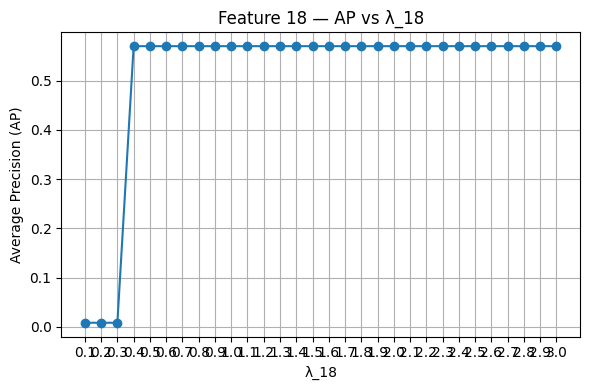

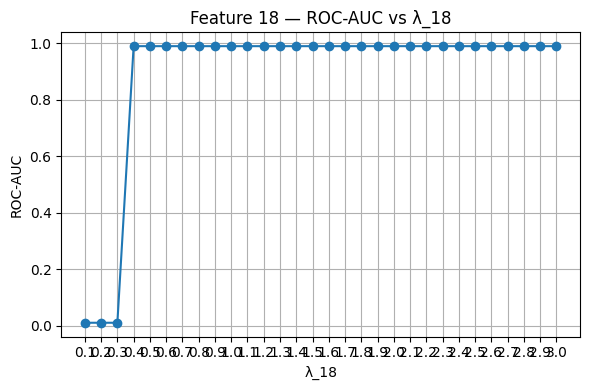

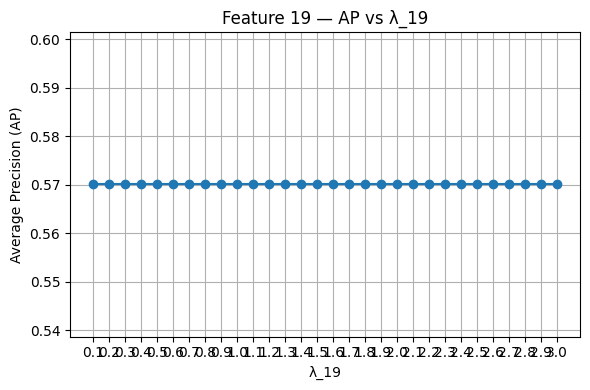

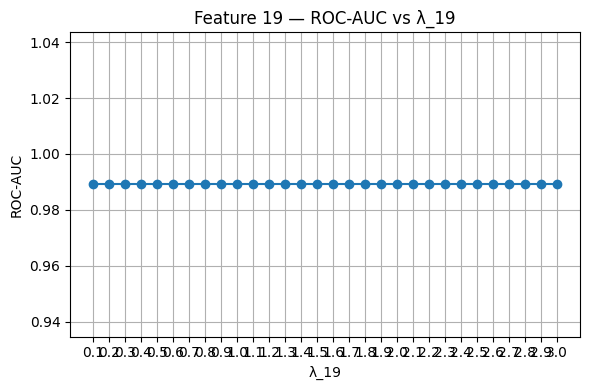

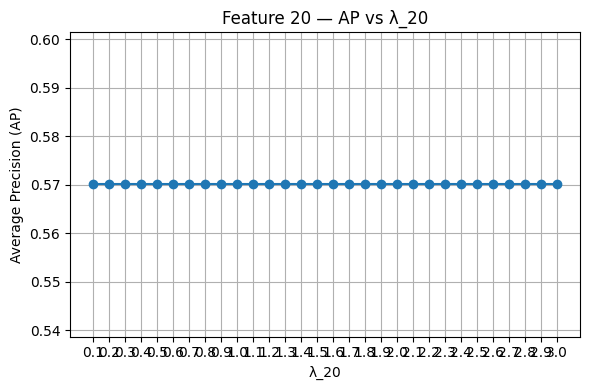

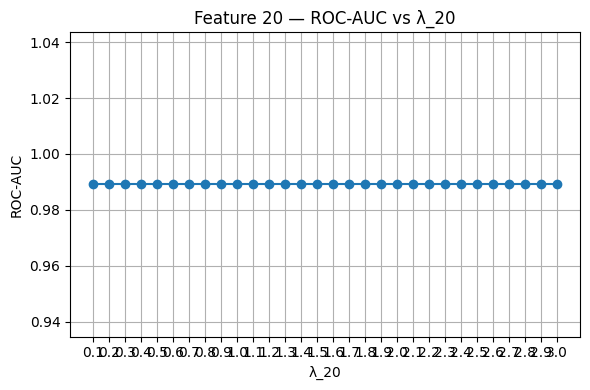

In [ ]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
     # =======================
    candidates = [0.1, 0.2, 0.3, 0.4, 0.5,
                  0.6, 0.7, 0.8, 0.9, 1.0,
                  1.1, 1.2, 1.3, 1.4, 1.5,
                  1.6, 1.7, 1.8, 1.9, 2.0,
                  2.1, 2.2, 2.3, 2.4, 2.5,
                  2.6, 2.7, 2.8, 2.9, 3.0]
    # List of candidate values for λ

    # =======================
    #2) Loading and Preprocessing
    # =======================
    mat = loadmat('german_1_14_varianh1.mat')
    full_data = mat['trandata']       # shape = (n_samples, 21)
    X11 = full_data[:, :20]                   # First 20 columns
    y11 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    # 3) Normalize only the features (columns 1, 4, 7, 10, 12, 15)
    numeric_idx = [1, 4, 7, 10, 12, 15]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X11[:, numeric_idx] = scaler.fit_transform(X11[:, numeric_idx])

    # ================================
    #4) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas(
        X11, y11, X_tem1, candidates, metric_name='AP'
    )
    print("=== Best Lambdas for AP for G1 ===")
    print(best_lams_ap)

    # ================================
    #5) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas(
        X11, y11, X_tem1, candidates, metric_name='ROC'
    )
    print("=== Best Lambdas for ROC-AUC for G1===")
    print(best_lams_roc)

    # ============================================
    #6) Draw graphs for each feature and each criterion
    # ============================================
    m = X11.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

# 🔵 New Approach for h2

### 2. runing algo

In [ ]:
# Conver h2_indices to python list
X_tem2 = h2_indices.tolist()

In [ ]:
# this is for best lammda list for TOP AP
if __name__ == "__main__":
    lammda = [3.8, 1.5, 0.1, 0.1, 0.1, 0.7]

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X22 = full_data[:, :6]                   # First 6 columns
    y22 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X22[:, 1:] = scaler.fit_transform(X22[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda
    out_scores22 = NEW_WNCROD(X22, X_tem2, lammda)

    # 5) Extract true labels only for X_tem
    y_true22 = y22[X_tem2]

    # 6) Compute metrics
    roc_auc22 = roc_auc_score(y_true22, out_scores22)
    ap22      = average_precision_score(y_true22, out_scores22)

    print(f"ROC-AUC: {roc_auc22:.4f}")
    print(f"Average Precision (AP): {ap22:.4f}")

ROC-AUC: 0.9848
Average Precision (AP): 0.8496


In [ ]:
# this is for best lammda list for TOP ROC-AUC
if __name__ == "__main__":
    lammda = [0.1, 4.1, 0.1, 1.1, 0.1, 0.9]

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X22 = full_data[:, :6]                   # First 6 columns
    y22 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X22[:, 1:] = scaler.fit_transform(X22[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda
    out_scores22 = NEW_WNCROD(X22, X_tem2, lammda)

    # 5) Extract true labels only for X_tem
    y_true22 = y22[X_tem2]

    # 6) Compute metrics
    roc_auc22 = roc_auc_score(y_true22, out_scores22)
    ap22      = average_precision_score(y_true22, out_scores22)

    print(f"ROC-AUC: {roc_auc22:.4f}")
    print(f"Average Precision (AP): {ap22:.4f}")

ROC-AUC: 0.9981
Average Precision (AP): 0.9424


### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [ ]:
def greedy_search_lambdas2(X: np.ndarray,
                          y: np.ndarray,
                          X_tem: list[int],
                          candidates: list[float],
                          metric_name2: str = 'AP'):

    m = X.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true = y[X_tem]

    # Selecting the criterion function
    if metric_name2.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name2.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name2 must be 'AP' or 'ROC'")

    # Loop over each feature with progress bar
    for j in tqdm(range(m), desc=f"Greedy Search ({metric_name2})", unit="feat"):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X, X_tem, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix

Greedy Search (AP): 100%|██████████| 6/6 [1:33:52<00:00, 938.71s/feat]


=== Best Lambdas for AP ===
[3.8 1.5 0.1 0.1 0.1 0.7]


Greedy Search (ROC): 100%|██████████| 6/6 [1:33:16<00:00, 932.68s/feat]


=== Best Lambdas for ROC-AUC ===
[0.1 4.1 0.1 1.1 0.1 0.9]


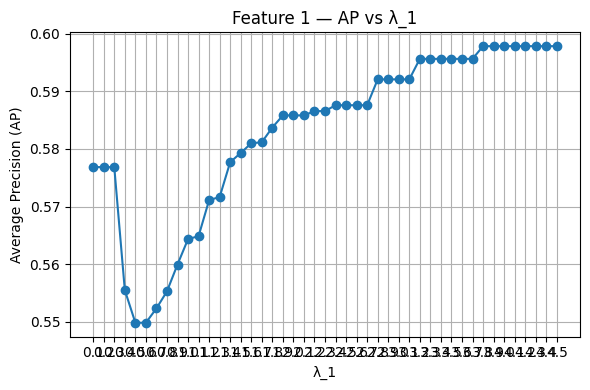

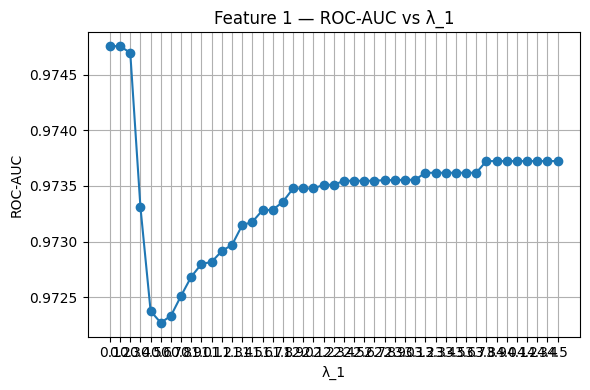

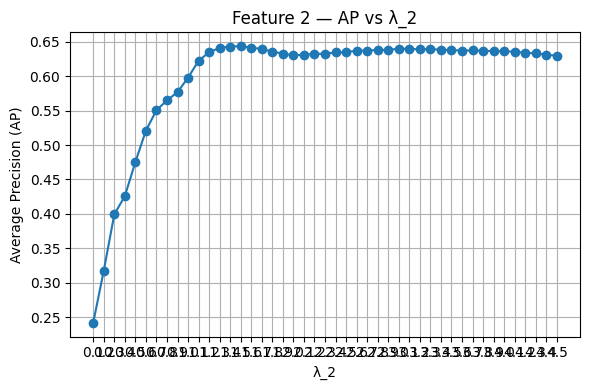

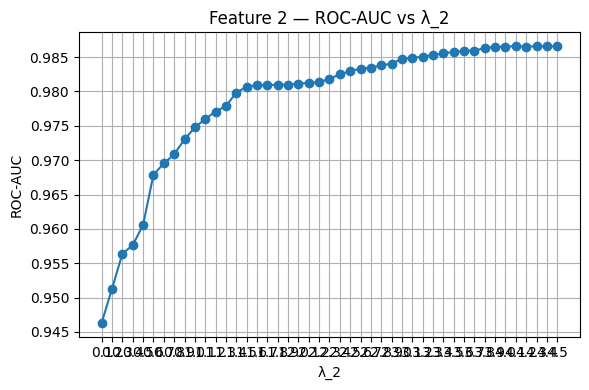

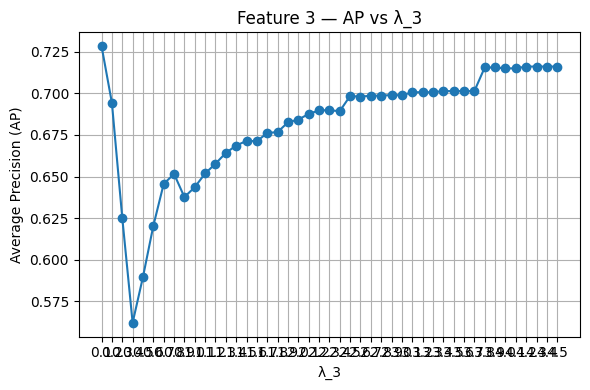

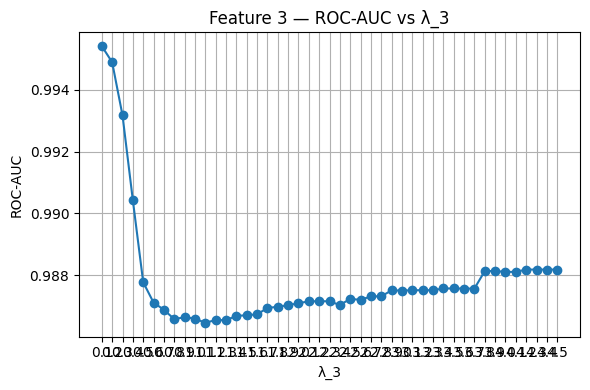

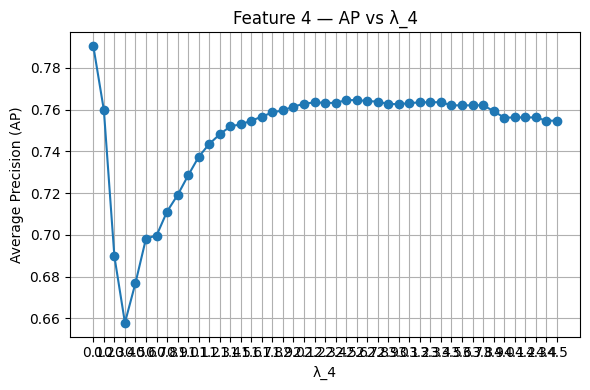

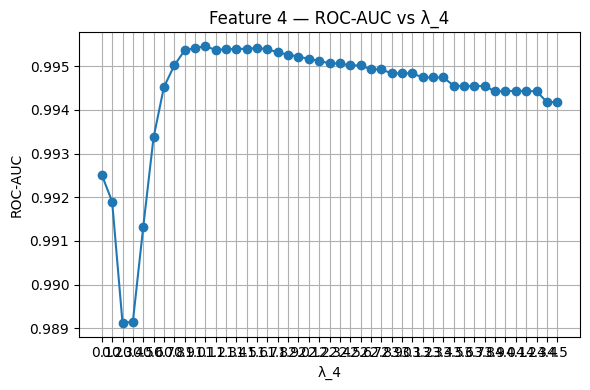

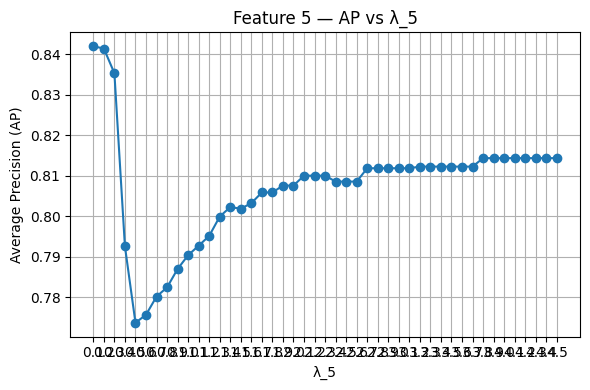

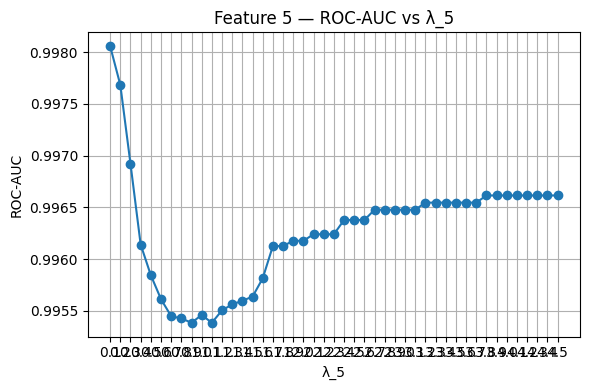

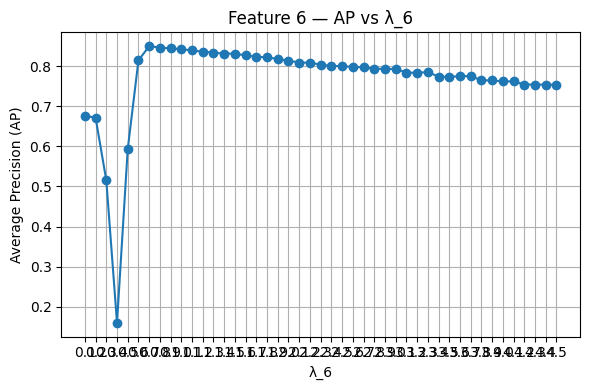

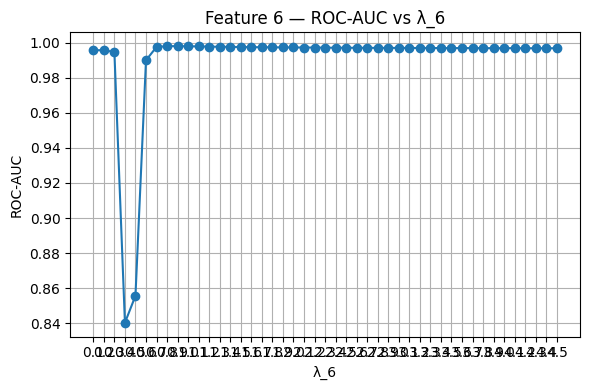

In [ ]:
if __name__ == "__main__":
    # =======================
    # 1) Setting the parameters
    # =======================
    candidates = [round(0.1 * i, 1) for i in range(1, 46)]  # 0.1 تا 4.5

    # =======================
    # 2) Loading and Preprocessing
    # =======================
    mat = loadmat('thyroid.mat')
    full_data = mat['trandata']       # shape = (n_samples, 7)
    X22 = full_data[:, :6]                   # First 6 columns
    y22 = full_data[:, 6].astype(int)        # Column 7 (index 6)

    scaler = MinMaxScaler()
    X22[:, 1:] = scaler.fit_transform(X22[:, 1:])

    # X_tem2 باید قبل از این تعریف شده باشه
    # مثال: X_tem2 = np.arange(len(X22))

    # ================================
    # 3) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas2(
        X22, y22, X_tem2, candidates, metric_name2='AP'
    )
    print("=== Best Lambdas for AP ===")
    print(best_lams_ap)

    # ================================
    # 4) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas2(
        X22, y22, X_tem2, candidates, metric_name2='ROC'
    )
    print("=== Best Lambdas for ROC-AUC ===")
    print(best_lams_roc)

    # ============================================
    # 5) Draw graphs for each feature and each criterion
    # ============================================
    m = X22.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

# 🔵 New Approach for h3

### 2. runing algo

In [ ]:
# Conver h3_indices to python list
X_tem3 = h3_indices.tolist()

In [ ]:
# this is for best lammda list for TOP AP
if __name__ == "__main__":

    lammda = [0.3, 3.0, 0.1, 5.0, 4.7, 3.1]

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X33 = full_data[:, :6]                   # First 6 columns
    y33 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X33[:, 1:] = scaler.fit_transform(X33[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores33 = NEW_WNCROD(X33, X_tem3, lammda)

    # 5) Extract true labels only for X_tem
    y_true33 = y33[X_tem3]

    # 6) Compute metrics
    roc_auc33 = roc_auc_score(y_true33, out_scores33)
    ap33      = average_precision_score(y_true33, out_scores33)

    print(f"ROC-AUC: {roc_auc33:.4f}")
    print(f"Average Precision (AP): {ap33:.4f}")

ROC-AUC: 0.9957
Average Precision (AP): 0.8886


In [ ]:
# this is for best lammda list for TOP ROC-AUC
if __name__ == "__main__":

    lammda = [4.8, 5.0, 0.1, 5.0, 0.7, 1.4]

    # 1) Load data
    mat       = loadmat('thyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X33 = full_data[:, :6]                   # First 6 columns
    y33 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X33[:, 1:] = scaler.fit_transform(X33[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores33 = NEW_WNCROD(X33, X_tem3, lammda)

    # 5) Extract true labels only for X_tem
    y_true33 = y33[X_tem3]

    # 6) Compute metrics
    roc_auc33 = roc_auc_score(y_true33, out_scores33)
    ap33      = average_precision_score(y_true33, out_scores33)

    print(f"ROC-AUC: {roc_auc33:.4f}")
    print(f"Average Precision (AP): {ap33:.4f}")

ROC-AUC: 0.9982
Average Precision (AP): 0.8930


### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [ ]:
def greedy_search_lambdas3(X33: np.ndarray,
                          y33: np.ndarray,
                          X_tem3: list[int],
                          candidates: list[float],
                          metric_name3: str = 'AP'):

    m = X33.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true3 = y33[X_tem3]

    # Selecting the criterion function
    if metric_name3.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name3.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name3 must be 'AP' or 'ROC'")

    # Loop over each feature
    for j in range(m):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X33, X_tem3, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true3, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix

=== Best Lambdas for AP ===
[0.3 3.  0.1 5.  4.7 3.1]
=== Best Lambdas for ROC-AUC ===
[4.8 5.  0.1 5.  0.7 1.4]


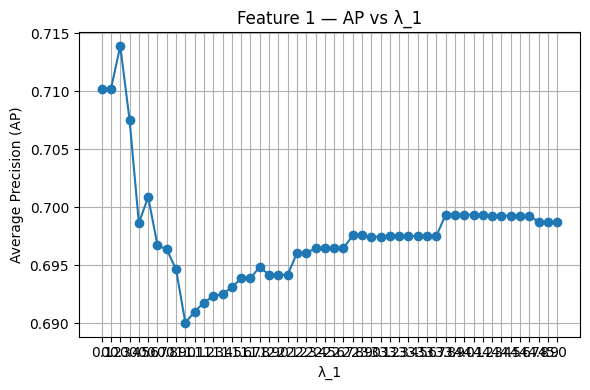

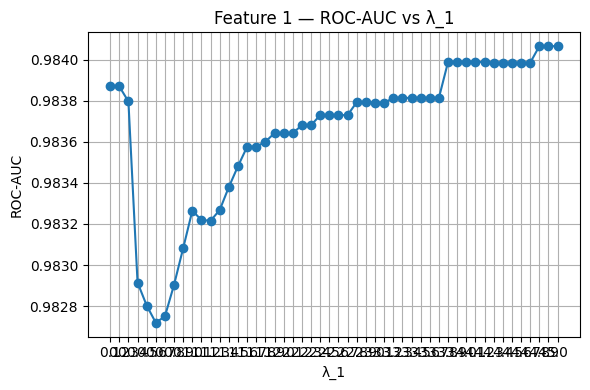

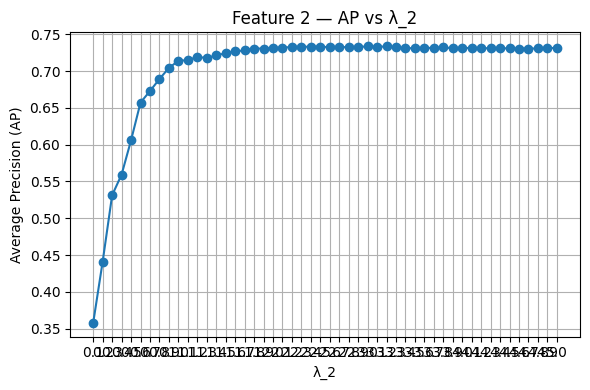

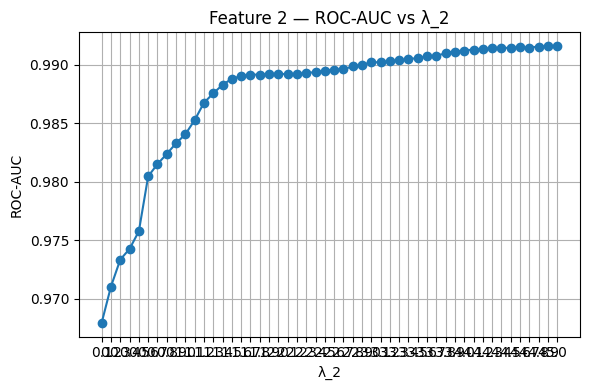

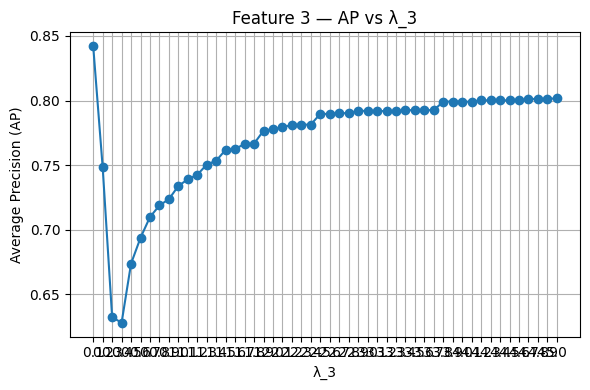

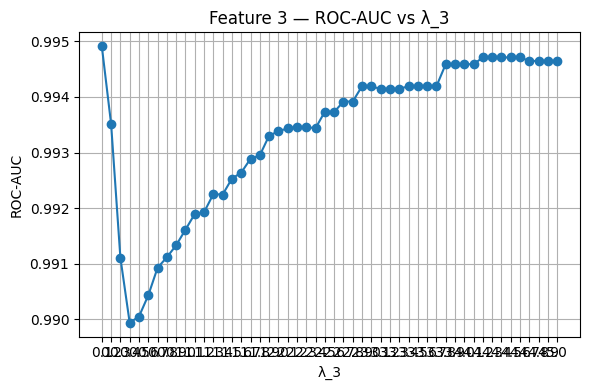

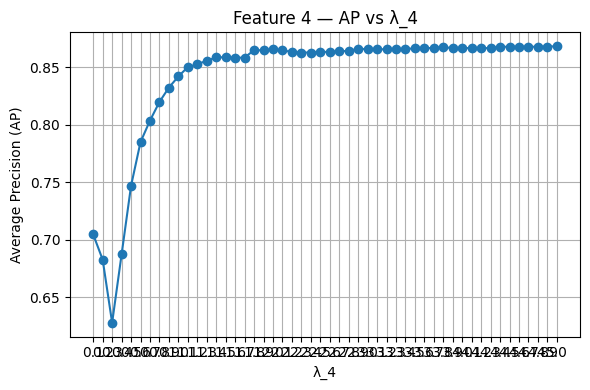

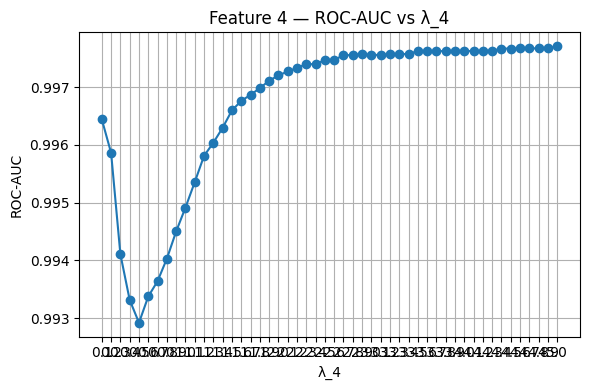

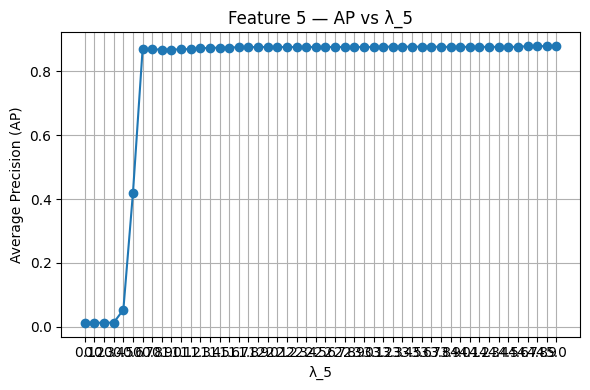

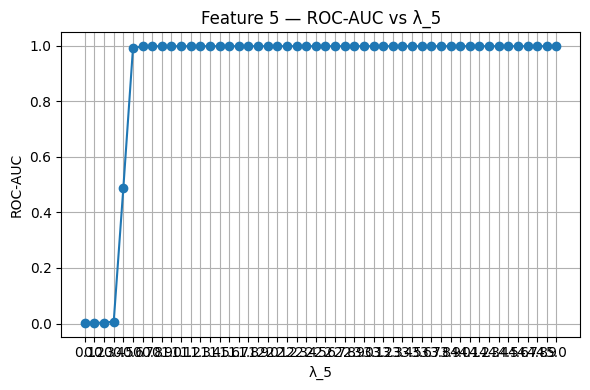

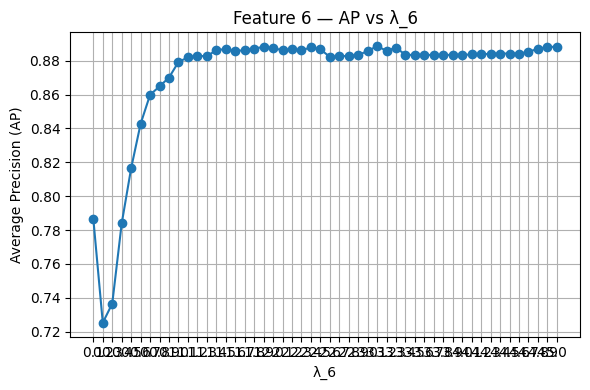

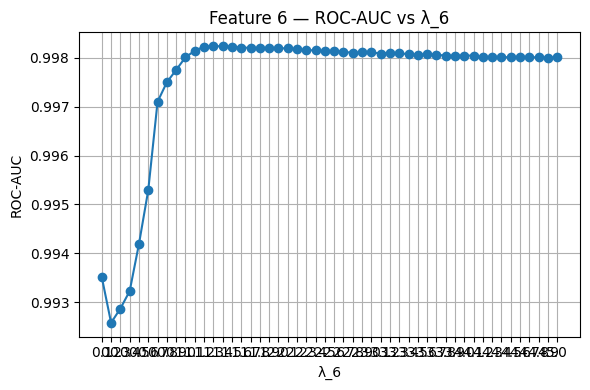

In [ ]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
    # =======================
    # List of candidate values for λ
    candidates = [0.1, 0.2, 0.3, 0.4, 0.5,
                  0.6, 0.7, 0.8, 0.9, 1.0,
                  1.1, 1.2, 1.3, 1.4, 1.5,
                  1.6, 1.7, 1.8, 1.9, 2.0,
                  2.1, 2.2, 2.3, 2.4, 2.5,
                  2.6, 2.7, 2.8, 2.9, 3.0,
                  3.1, 3.2, 3.3, 3.4, 3.5]

    # =======================
    #2) Loading and Preprocessing
    # =======================
    mat = loadmat('german_1_14_varianh1.mat')
    full_data = mat['trandata']       # shape = (n_samples, 7)
    X33 = full_data[:, :20]                   # First 20 columns
    y33 =  full_data[:, 20].astype(int)       # Column 21 (index 20)

    numeric_idx = [1, 4, 7, 10, 12, 15, 17]
    scaler = MinMaxScaler()
    # بردار ستون‌های عددی را جدا می‌کنیم و نرمال می‌کنیم
    X33[:, numeric_idx] = scaler.fit_transform(X33[:, numeric_idx])

    # ================================
    #3) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas3(
        X33, y33, X_tem3, candidates, metric_name3='AP'
    )
    print("=== Best Lambdas for AP ===")
    print(best_lams_ap)

    # ================================
    #4) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas3(
        X33, y33, X_tem3, candidates, metric_name3='ROC'
    )
    print("=== Best Lambdas for ROC-AUC ===")
    print(best_lams_roc)

    # ============================================
    #5) Draw graphs for each feature and each criterion
    # ============================================
    m = X33.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()